# CTDDG diagnostics — toxicity-aware

Original Block 16, unchanged. Run after a checkpoint and logs have been saved by the pretraining notebook. This notebook does not launch training.

In [ ]:
from pathlib import Path

# Original project/output paths from Block 1 (no dataset or model initialization needed).
ROOT = Path("/home/muhamed/repo/CTDDG/REWORKED_CODE")
PRETRAINING_DIR = ROOT / "PRETRAINING_OUTPUT"


## TRAINING VERIFICATION AND ANALYSIS

BLOCK 16: CTDDG PRETRAINING VERIFICATION

[OUTPUT FILES]
Configuration     : FOUND    (0.00 MB)
Checkpoint        : FOUND    (79.93 MB)
Best model        : FOUND    (26.66 MB)
Final model       : FOUND    (26.66 MB)
Training log      : FOUND    (0.32 MB)
Validation log    : FOUND    (0.03 MB)

[CHECKPOINT VERIFICATION]
Saved optimizer step: 161870
Saved epoch index: 5
Saved batch offset: 0
Batch size: 32
Training molecules: 1035981

[TRAINING PROGRESS]
Steps per epoch: 32374
Total target steps: 161870
Progress: 161,870/161,870
Completed epochs: 5.000/5
Completion: 100.00%

FULL TRAINING: COMPLETED

[MODEL WEIGHT VERIFICATION]
State dictionary tensors: 79
Approximate stored parameters: 6976184
Finite checkpoint weights: PASSED
Optimizer state entries: 49
Optimizer recovery state: PASSED

[EXPORTED MODEL VERIFICATION]
Best model checkpoint: PASSED
Best checkpoint step: 154750
Final model weights: PASSED
Final model step: 161870

[TRAINING LOG ANALYSIS]
Training log records: 1783
Validati

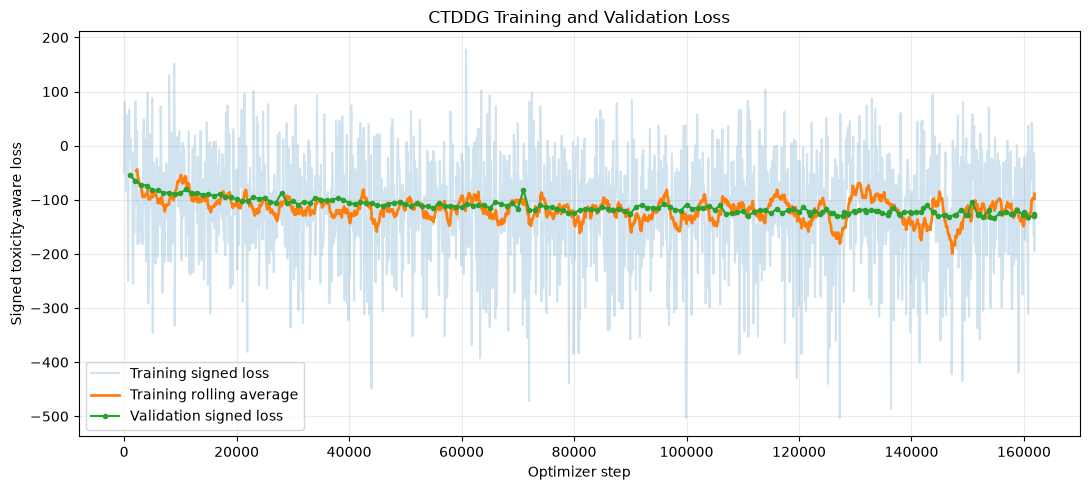

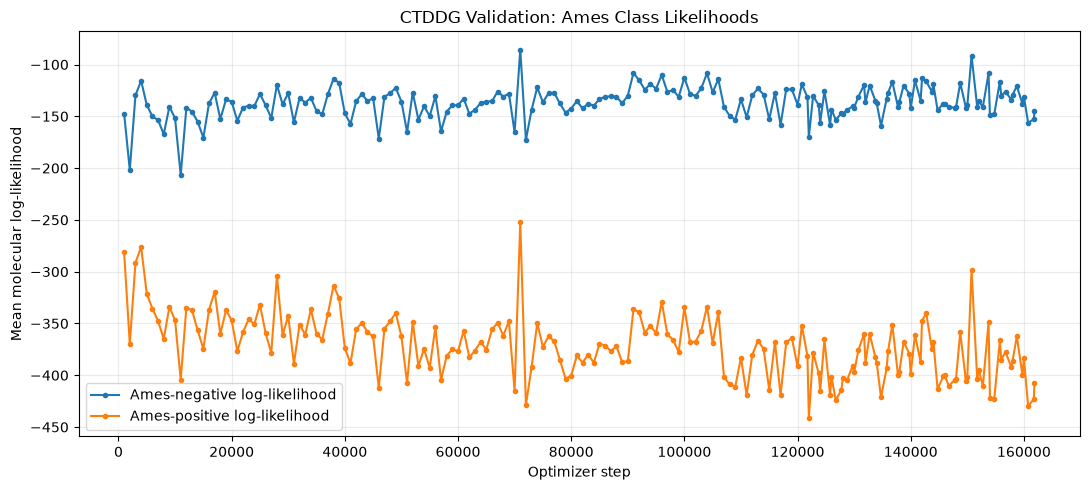


[AMES CLASS LIKELIHOOD CHANGES]
Ames-negative LL change: +2.3752
Ames-positive suppression: +126.1602
Negative-molecule likelihood increased
Positive-molecule likelihood decreased

Note: These likelihood changes alone do not establish the toxicity or validity of generated molecules.

BLOCK 16: FINAL STATUS
Training progress: 100.00%
Epochs: 5.000/5
Checkpoint integrity: PASSED
Training logs: PASSED
Validation logs: PASSED
Final model verified: True

Analysis outputs:
/home/muhamed/repo/CTDDG/REWORKED_CODE/PRETRAINING_OUTPUT/toxicity_aware/runs/ctddg_main_bs32_lambda2/analysis/training_loss.png
/home/muhamed/repo/CTDDG/REWORKED_CODE/PRETRAINING_OUTPUT/toxicity_aware/runs/ctddg_main_bs32_lambda2/analysis/ames_class_likelihoods.png
/home/muhamed/repo/CTDDG/REWORKED_CODE/PRETRAINING_OUTPUT/toxicity_aware/runs/ctddg_main_bs32_lambda2/analysis/training_analysis.json

PRETRAINING COMPLETE AND VERIFIED!
Ready for Block 17: Molecular Generation

BLOCK 16 ANALYSIS COMPLETED!


In [17]:

# ============================================================
# BLOCK 16: CTDDG TRAINING VERIFICATION AND ANALYSIS
# ============================================================

import json
import math
from pathlib import Path
from datetime import datetime

import numpy as np
import torch
import matplotlib.pyplot as plt

# ============================================================
# 1. LOCATE TRAINING OUTPUTS
# ============================================================

RUN_DIR = (
    PRETRAINING_DIR
    / "toxicity_aware"
    / "runs"
    / "ctddg_main_bs32_lambda2"
)

CHECKPOINT_PATH = RUN_DIR / "checkpoint.pt"
BEST_PATH = RUN_DIR / "model_best.pt"
FINAL_PATH = RUN_DIR / "model_final.pt"

CONFIG_PATH = RUN_DIR / "config.json"
TRAIN_LOG_PATH = RUN_DIR / "train_log.jsonl"
VAL_LOG_PATH = RUN_DIR / "validation_log.jsonl"

ANALYSIS_DIR = RUN_DIR / "analysis"
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

EXPECTED_EPOCHS = 5

print("=" * 70)
print("BLOCK 16: CTDDG PRETRAINING VERIFICATION")
print("=" * 70)

print("\n[OUTPUT FILES]")

files = {
    "Configuration": CONFIG_PATH,
    "Checkpoint": CHECKPOINT_PATH,
    "Best model": BEST_PATH,
    "Final model": FINAL_PATH,
    "Training log": TRAIN_LOG_PATH,
    "Validation log": VAL_LOG_PATH,
}

for name, path in files.items():

    status = (
        "FOUND" if path.exists()
        else "MISSING"
    )

    size_mb = (
        path.stat().st_size / 1024**2
        if path.exists()
        else 0
    )

    print(
        f"{name:18s}: "
        f"{status:8s} "
        f"({size_mb:.2f} MB)"
    )

assert CONFIG_PATH.exists()
assert CHECKPOINT_PATH.exists()

# ============================================================
# 2. LOAD CHECKPOINT ON CPU
# ============================================================

print("\n[CHECKPOINT VERIFICATION]")

# Only load checkpoint files generated by your own code.
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

config = json.loads(
    CONFIG_PATH.read_text(encoding="utf-8")
)

assert checkpoint["config"] == config

assert "model_state_dict" in checkpoint
assert "optimizer_state_dict" in checkpoint

saved_step = int(checkpoint["step"])
saved_epoch = int(checkpoint["epoch"])
saved_offset = int(checkpoint["batch_offset"])

batch_size = int(config["batch_size"])
train_count = int(config["train_count"])

# Reproduce the exact length-bucket counting
# used by make_epoch_batches in Block 12.
bucket_size = max(batch_size * 32, 256)

full_buckets, remainder = divmod(
    train_count,
    bucket_size
)

steps_per_epoch = (
    full_buckets * (bucket_size // batch_size)
    + remainder // batch_size
)

total_target_steps = (
    EXPECTED_EPOCHS * steps_per_epoch
)

completed_epochs = (
    saved_step / steps_per_epoch
)

progress_percent = (
    100 * saved_step / total_target_steps
)

training_complete = (
    saved_step >= total_target_steps
)

print("Saved optimizer step:", saved_step)
print("Saved epoch index:", saved_epoch)
print("Saved batch offset:", saved_offset)
print("Batch size:", batch_size)
print("Training molecules:", train_count)

print("\n[TRAINING PROGRESS]")

print("Steps per epoch:", steps_per_epoch)
print("Total target steps:", total_target_steps)

print(
    f"Progress: {saved_step:,}/"
    f"{total_target_steps:,}"
)

print(
    f"Completed epochs: "
    f"{completed_epochs:.3f}/{EXPECTED_EPOCHS}"
)

print(
    f"Completion: {progress_percent:.2f}%"
)

if training_complete:
    print("\nFULL TRAINING: COMPLETED")
else:
    print("\nFULL TRAINING: NOT YET COMPLETE")
    print(
        "Resume Block 15 if it has stopped. "
        "Do not consider these final weights yet."
    )

# ============================================================
# 3. VERIFY MODEL WEIGHTS
# ============================================================

print("\n[MODEL WEIGHT VERIFICATION]")

model_state = checkpoint["model_state_dict"]

assert len(model_state) > 0

parameter_count = sum(
    tensor.numel()
    for name, tensor in model_state.items()
    if (
        torch.is_floating_point(tensor)
        and not name.endswith("running_mean")
        and not name.endswith("running_var")
        and not name.endswith("num_batches_tracked")
    )
)

nonfinite_tensors = []

for name, tensor in model_state.items():

    if torch.is_floating_point(tensor):

        if not torch.isfinite(tensor).all():
            nonfinite_tensors.append(name)

print("State dictionary tensors:", len(model_state))
print("Approximate stored parameters:", parameter_count)

assert not nonfinite_tensors, (
    "Non-finite model weights detected: "
    + str(nonfinite_tensors)
)

print("Finite checkpoint weights: PASSED")

optimizer_state = checkpoint[
    "optimizer_state_dict"
]

assert "state" in optimizer_state
assert "param_groups" in optimizer_state

print(
    "Optimizer state entries:",
    len(optimizer_state["state"])
)

assert len(optimizer_state["state"]) > 0

print("Optimizer recovery state: PASSED")

# ============================================================
# 4. VERIFY BEST AND FINAL MODEL FILES
# ============================================================

print("\n[EXPORTED MODEL VERIFICATION]")

best_model_verified = False
final_model_verified = False

if BEST_PATH.exists():

    best_checkpoint = torch.load(
        BEST_PATH,
        map_location="cpu",
        weights_only=False
    )

    assert "model_state_dict" in best_checkpoint

    best_step = int(best_checkpoint["step"])

    assert best_step <= saved_step

    best_model_verified = True

    print("Best model checkpoint: PASSED")
    print("Best checkpoint step:", best_step)

else:
    print("Best model checkpoint: NOT FOUND")

if FINAL_PATH.exists():

    final_checkpoint = torch.load(
        FINAL_PATH,
        map_location="cpu",
        weights_only=False
    )

    assert "model_state_dict" in final_checkpoint

    final_step = int(final_checkpoint["step"])

    assert final_step == saved_step, (
        "Final model does not match the "
        "latest checkpoint step"
    )

    final_state = final_checkpoint["model_state_dict"]

    assert set(final_state) == set(model_state)

    for name in model_state:

        assert torch.equal(
            final_state[name],
            model_state[name]
        ), (
            f"Final weight mismatch: {name}"
        )

    final_model_verified = True

    print("Final model weights: PASSED")
    print("Final model step:", final_step)

else:
    print("Final model weights: NOT YET EXPORTED")

if training_complete and not final_model_verified:
    print(
        "WARNING: Target step reached, "
        "but model_final.pt is missing. "
        "The final export needs to be completed."
    )

# ============================================================
# 5. LOAD TRAINING AND VALIDATION LOGS
# ============================================================

print("\n[TRAINING LOG ANALYSIS]")

def read_jsonl(path):

    results = []

    if not path.exists():
        return results

    with path.open("r", encoding="utf-8") as f:

        for line in f:

            if not line.strip():
                continue

            try:
                results.append(json.loads(line))
            except json.JSONDecodeError:
                # An actively written last line may be partial.
                print("Skipping incomplete log line")

    # Keep the latest record per optimizer step.
    by_step = {
        int(item["step"]): item
        for item in results
    }

    return [
        by_step[key]
        for key in sorted(by_step)
    ]


train_history = read_jsonl(
    TRAIN_LOG_PATH
)

val_history = read_jsonl(
    VAL_LOG_PATH
)

print("Training log records:", len(train_history))
print("Validation log records:", len(val_history))

assert len(train_history) > 0
assert len(val_history) > 0

train_steps_arr = np.array([
    item["step"]
    for item in train_history
])

train_losses = np.array([
    item["loss"]
    for item in train_history
], dtype=np.float64)

val_steps_arr = np.array([
    item["step"]
    for item in val_history
])

val_losses = np.array([
    item["val_loss"]
    for item in val_history
], dtype=np.float64)

assert np.isfinite(train_losses).all()
assert np.isfinite(val_losses).all()

assert train_steps_arr[-1] <= saved_step
assert val_steps_arr[-1] <= saved_step

print("Finite logged losses: PASSED")

print("\n[LAST TRAINING RECORDS]")

for item in train_history[-5:]:

    print(
        f"Step {item['step']:>7,} | "
        f"Loss {item['loss']:>+11.4f} | "
        f"Gradient {item['grad_norm']:>9.3f} | "
        f"LR {item['lr']:.7f}"
    )

print("\n[LAST VALIDATION RECORDS]")

for item in val_history[-5:]:

    print(
        f"Step {item['step']:>7,} | "
        f"Signed loss {item['val_loss']:>+11.4f} | "
        f"Neg LL {item['val_neg_ll_mean']:>+11.4f} | "
        f"Pos LL {item['val_pos_ll_mean']:>+11.4f}"
    )

# ============================================================
# 6. PLOT TRAINING AND VALIDATION LOSSES
# ============================================================

print("\n[GENERATING LOSS CURVES]")

# Rolling average helps visualize noisy
# signed batch losses.
window = min(25, len(train_losses))

if window > 1:

    smooth_losses = np.convolve(
        train_losses,
        np.ones(window) / window,
        mode="valid"
    )

    smooth_steps = train_steps_arr[
        window - 1:
    ]

else:
    smooth_losses = train_losses
    smooth_steps = train_steps_arr

plt.figure(figsize=(11, 5))

plt.plot(
    train_steps_arr,
    train_losses,
    alpha=0.20,
    label="Training signed loss"
)

plt.plot(
    smooth_steps,
    smooth_losses,
    linewidth=2,
    label="Training rolling average"
)

plt.plot(
    val_steps_arr,
    val_losses,
    marker="o",
    markersize=3,
    label="Validation signed loss"
)

plt.xlabel("Optimizer step")
plt.ylabel("Signed toxicity-aware loss")
plt.title("CTDDG Training and Validation Loss")

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

loss_plot = (
    ANALYSIS_DIR / "training_loss.png"
)

plt.savefig(
    loss_plot,
    dpi=180,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 7. PLOT SEPARATE AMES-CLASS LIKELIHOODS
# ============================================================

neg_ll = np.array([
    item["val_neg_ll_mean"]
    for item in val_history
], dtype=np.float64)

pos_ll = np.array([
    item["val_pos_ll_mean"]
    for item in val_history
], dtype=np.float64)

assert np.isfinite(neg_ll).all()
assert np.isfinite(pos_ll).all()

plt.figure(figsize=(11, 5))

plt.plot(
    val_steps_arr,
    neg_ll,
    marker="o",
    markersize=3,
    label="Ames-negative log-likelihood"
)

plt.plot(
    val_steps_arr,
    pos_ll,
    marker="o",
    markersize=3,
    label="Ames-positive log-likelihood"
)

plt.xlabel("Optimizer step")
plt.ylabel("Mean molecular log-likelihood")
plt.title("CTDDG Validation: Ames Class Likelihoods")

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

class_plot = (
    ANALYSIS_DIR / "ames_class_likelihoods.png"
)

plt.savefig(
    class_plot,
    dpi=180,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 8. ANALYZE CLASS LIKELIHOOD CHANGES
# ============================================================

print("\n[AMES CLASS LIKELIHOOD CHANGES]")

negative_gain = (
    neg_ll[-1] - neg_ll[0]
)

positive_suppression = (
    pos_ll[0] - pos_ll[-1]
)

print(
    f"Ames-negative LL change: "
    f"{negative_gain:+.4f}"
)

print(
    f"Ames-positive suppression: "
    f"{positive_suppression:+.4f}"
)

if negative_gain > 0:
    print("Negative-molecule likelihood increased")
else:
    print("Negative-molecule likelihood did not increase")

if positive_suppression > 0:
    print("Positive-molecule likelihood decreased")
else:
    print("Positive-molecule likelihood did not decrease")

print(
    "\nNote: These likelihood changes alone do not "
    "establish the toxicity or validity of "
    "generated molecules."
)

# ============================================================
# 9. SAVE ANALYSIS REPORT
# ============================================================

report = {
    "run_name": RUN_DIR.name,
    "checkpoint_step": saved_step,
    "target_steps": total_target_steps,
    "completed_epochs": completed_epochs,
    "expected_epochs": EXPECTED_EPOCHS,
    "progress_percent": progress_percent,
    "training_complete": training_complete,
    "batch_size": batch_size,
    "tox_lambda": config["tox_lambda"],
    "checkpoint_verified": True,
    "best_model_verified": best_model_verified,
    "final_model_verified": final_model_verified,
    "training_log_records": len(train_history),
    "validation_log_records": len(val_history),
    "last_train_loss": float(train_losses[-1]),
    "last_val_loss": float(val_losses[-1]),
    "negative_ll_change": float(negative_gain),
    "positive_ll_suppression": float(
        positive_suppression
    ),
    "last_validation_step": int(
        val_steps_arr[-1]
    ),
    "analysis_note": (
        "Signed Equation 8 objective and per-class "
        "likelihoods do not establish generated "
        "molecule validity, diversity or toxicity."
    )
}

report_path = (
    ANALYSIS_DIR / "training_analysis.json"
)

report_path.write_text(
    json.dumps(report, indent=2),
    encoding="utf-8"
)

# ============================================================
# 10. FINAL STATUS
# ============================================================

print("\n" + "=" * 70)
print("BLOCK 16: FINAL STATUS")
print("=" * 70)

print(
    f"Training progress: "
    f"{progress_percent:.2f}%"
)

print(
    f"Epochs: "
    f"{completed_epochs:.3f}/{EXPECTED_EPOCHS}"
)

print("Checkpoint integrity: PASSED")
print("Training logs: PASSED")
print("Validation logs: PASSED")

print(
    "Final model verified:",
    final_model_verified
)

print("\nAnalysis outputs:")
print(loss_plot)
print(class_plot)
print(report_path)

if training_complete and final_model_verified:

    print("\nPRETRAINING COMPLETE AND VERIFIED!")
    print("Ready for Block 17: Molecular Generation")

elif training_complete:

    print("\nTraining steps complete.")
    print("Final model export still needs attention.")

else:

    print("\nPRETRAINING NOT FINISHED.")
    print(
        "If Block 15 stopped, rerun it "
        "to resume from the saved checkpoint."
    )

print("\nBLOCK 16 ANALYSIS COMPLETED!")
